<b><h2><center>Bike Sharing Case Study</center></h2></b>

## Problem Statement

### Context:

Bike-sharing systems are a new generation of traditional bike rentals where the whole process from membership, rental and return has become automatic. Through these systems, the user can easily rent a bike from a particular position and return to another position. Currently, there are about over 500 bike-sharing programs around the world which are composed of over 500 thousand bicycles. Today, there exists a great interest in these systems due to their important role in traffic, environmental, and health issues.


### Objective:
'Travel Along' is a new bike-sharing company and wants to expand its customer count and provide better services at a reasonable cost. They have conducted several surveys and collated the data about weather, weekends, holidays, etc. from the past 2 years.

As a recently hired data scientist at 'Travel Along', you have been asked to analyze the patterns in the data and figure out the key areas which can help the organization to grow and manage the customer demands. Further, you need to use this information to predict the count of bikes shared so that the company can take prior decisions for surge hours.
- What are the different factors which affect the target variable? What business recommendations can we give based on the analysis?
- How can we use different ensemble techniques - Bagging, Boosting, and Stacking to build a model to predict the count of bikes rented?

### Data Description:

The bike-sharing rental process is highly correlated to the environmental and seasonal settings. For instance, weather conditions, precipitation, the day of week, season, the hour of the day, etc. can affect the rental behaviors.

- instant: record index
- dteday : date
- season : season (1:spring, 2:summer, 3:fall, 4:winter)
- yr : year (0: 2011, 1:2012)
- mnth : month ( 1 to 12)
- hr : hour (0 to 23)
- holiday : whether the day is holiday or not
- weekday : day of the week
- workingday : if day is neither weekend nor holiday then 1, otherwise is 0.
- weathersit :
	- 1: Clear, Few clouds, Partly cloudy
	- 2: Mist + Cloudy, Mist + Broken clouds, Mist + Few clouds, Mist
	- 3: Light Snow, Light Rain + Thunderstorm + Scattered clouds, Light Rain + Scattered clouds
	- 4: Heavy Rain + Ice Pallets + Thunderstorm + Mist, Snow + Fog
- temp : Normalized temperature in Celsius. The values are divided by 41 (max)
- atemp: Normalized feeling temperature in Celsius. The values are divided to 50 (max). The “feel like” temperature relies on environmental data including the ambient air temperature, relative humidity, and wind speed to determine how weather conditions feel to bare skin.
- hum: Normalized humidity. The values are divided by 100 (max)
- windspeed: Normalized wind speed. The values are divided by 67 (max)
- casual: count of casual users
- registered: count of registered users
- cnt: count of total rental bikes including both casual and registered

## Importing necessary libraries

**Importing the libraries required**

In [1]:
# Libraries

import numpy as np
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore')

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor, GradientBoostingRegressor, AdaBoostRegressor
from xgboost import XGBRegressor
from sklearn import metrics
from sklearn.model_selection import train_test_split, GridSearchCV

## Reading the dataset

In [11]:
# Load Dataset

data = pd.read_csv('hour.csv')

## Overview of the dataset

### View the first 5 rows of the dataset

In [12]:
data.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


### Check data types and number of non-null values for each column

In [19]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   season      17379 non-null  int64  
 1   yr          17379 non-null  int64  
 2   mnth        17379 non-null  int64  
 3   hr          17379 non-null  int64  
 4   holiday     17379 non-null  int64  
 5   weekday     17379 non-null  int64  
 6   workingday  17379 non-null  int64  
 7   weathersit  17379 non-null  int64  
 8   temp        17379 non-null  float64
 9   atemp       17379 non-null  float64
 10  hum         17379 non-null  float64
 11  windspeed   17379 non-null  float64
 12  casual      17379 non-null  int64  
 13  registered  17379 non-null  int64  
 14  cnt         17379 non-null  int64  
dtypes: float64(4), int64(11)
memory usage: 2.0 MB


- We can see that there are total of 17 columns and 17,379 rows in the dataset.
- All columns' data type is either integer or float except one column - 'dteday' which is of the object type.
- The number of non-null values of each column is equal to the number of total rows in the dataset i.e. no null value. We can further confirm this using `isna()` method.

In [20]:
data.isna().sum()

,0
season,0
yr,0
mnth,0
hr,0
holiday,0
weekday,0
workingday,0
weathersit,0
temp,0
atemp,0


- There are no missing values in the data.

### Summary of the dataset

In [21]:
# summary

data[['temp', 'atemp', 'hum', 'windspeed', 'cnt']].describe().T

,count,mean,std,min,25%,50%,75%,max
temp,17379.0,0.496987,0.192556,0.02,0.3400,0.5000,0.6600,1.0000
atemp,17379.0,0.475775,0.171850,0.00,0.3333,0.4848,0.6212,1.0000
hum,17379.0,0.627229,0.192930,0.00,0.4800,0.6300,0.7800,1.0000
windspeed,17379.0,0.190098,0.122340,0.00,0.1045,0.1940,0.2537,0.8507
cnt,17379.0,189.463088,181.387599,1.00,40.0000,142.0000,281.0000,977.0000


- The mean and median value of temperature is approx 0.50
- The mean and median value for 'atemp' is approx 0.47 and 0.48 respectively
- The mean and median value for 'hum' is approx 0.627 and 0.63 respectively
- Wind speed has some extreme values at the right end
- The target variable seems to have skewed distribution as higher values are on the right. We will explore this further.

### Number of unique values in each column

In [22]:
data.nunique()

,0
season,4
yr,2
mnth,12
hr,24
holiday,2
weekday,7
workingday,2
weathersit,4
temp,50
atemp,65


- We can drop 'instant' column as it is an ID variable and will not add value to the model.
- We can drop 'dteday' column as it just contains dates of 731 days i.e. 2 years. This will not add value to the model.

In [ ]:
#Dropping two columns from the dataframe
data.drop(columns=['instant','dteday'], inplace=True)

In [24]:
# no of observations

cat_col = ['season', 'yr', 'holiday', 'workingday', 'weathersit']

for col in cat_col:
  print(data[col].value_counts())
  print('-'*30)

season
3    4496
2    4409
1    4242
4    4232
Name: count, dtype: int64
------------------------------
yr
1    8734
0    8645
Name: count, dtype: int64
------------------------------
holiday
0    16879
1      500
Name: count, dtype: int64
------------------------------
workingday
1    11865
0     5514
Name: count, dtype: int64
------------------------------
weathersit
1    11413
2     4544
3     1419
4        3
Name: count, dtype: int64
------------------------------


In [25]:
df = data.copy()

In [26]:
def histogram_boxplot(data, feature, figsize=(15, 10), kde=False, bins=None):
  f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2,
        sharex=True,
        gridspec_kw={"height_ratios": (0.25, 0.75)},
        figsize=figsize,
    )
  sns.boxplot(
        data=data, x=feature, ax=ax_box2, showmeans=True, color="violet"
    )
  sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2, bins=bins
    ) if bins else sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2
    )
  ax_hist2.axvline(
        data[feature].mean(), color="green", linestyle="--"
    )
  ax_hist2.axvline(
        data[feature].median(), color="black", linestyle="-"
    )

In [27]:
# function to create labeled barplots


def labeled_barplot(data, feature, perc=False, n=None):
    total = len(data[feature])
    count = data[feature].nunique()
    if n is None:
        plt.figure(figsize=(count + 2, 6))
    else:
        plt.figure(figsize=(n + 2, 6))

    plt.xticks(rotation=90, fontsize=15)
    ax = sns.countplot(
        data=data,
        x=feature,
        palette="Paired",
        order=data[feature].value_counts().index[:n],
    )

    for p in ax.patches:
        if perc == True:
            label = "{:.1f}%".format(
                100 * p.get_height() / total
            )
        else:
            label = p.get_height()

        x = p.get_x() + p.get_width() / 2
        y = p.get_height()

        ax.annotate(
            label,
            (x, y),
            ha="center",
            va="center",
            size=12,
            xytext=(0, 5),
            textcoords="offset points",
        )

    plt.show()

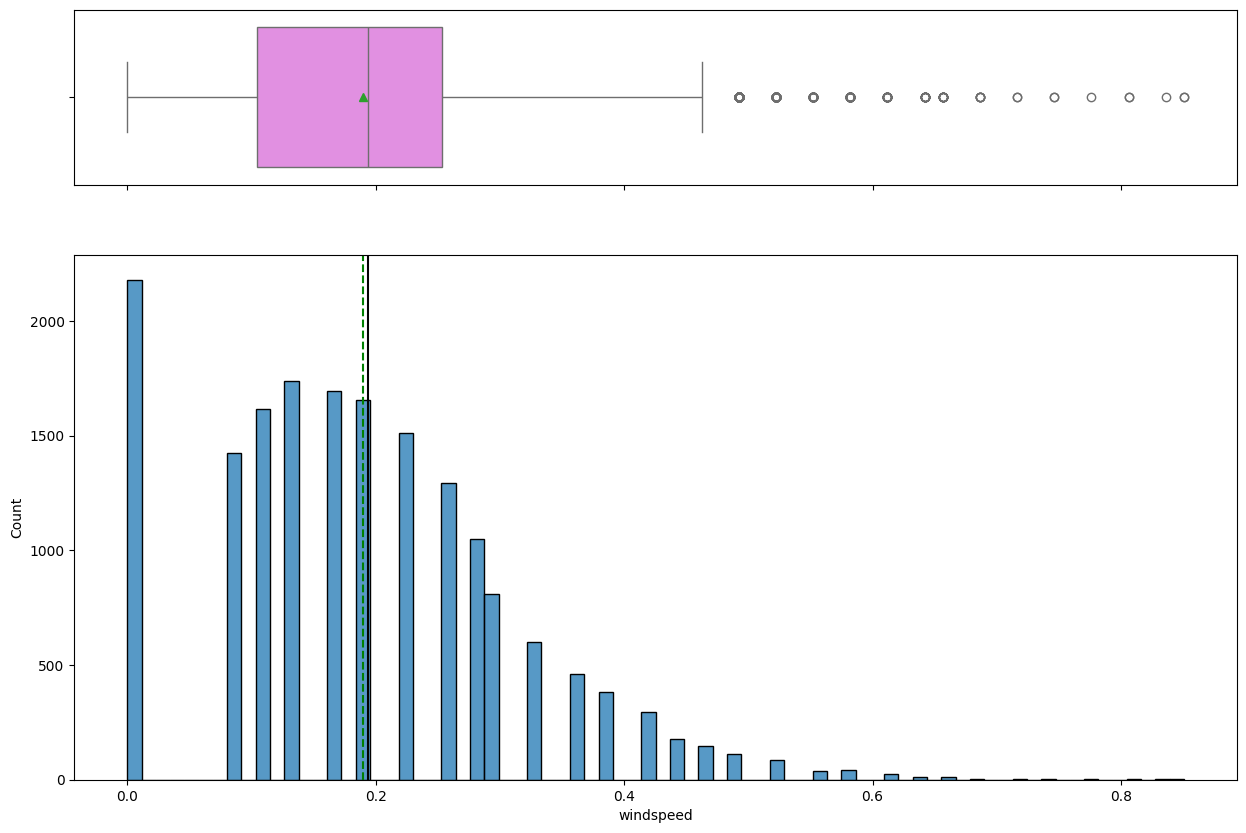

In [28]:
histogram_boxplot(data, 'windspeed')

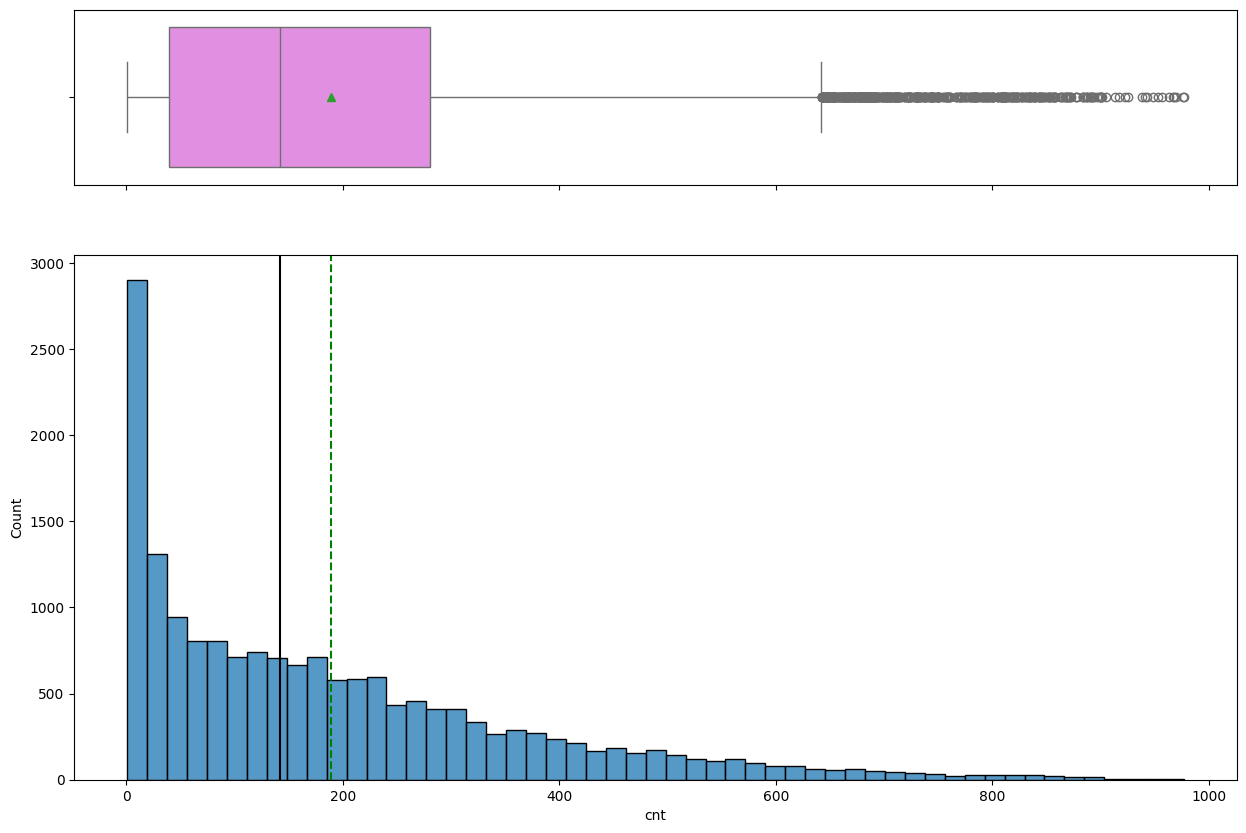

In [29]:
histogram_boxplot(data, 'cnt')

In [30]:
data['cnt'].nlargest()

,cnt
14773,977
14964,976
14748,970
14725,968
15084,967


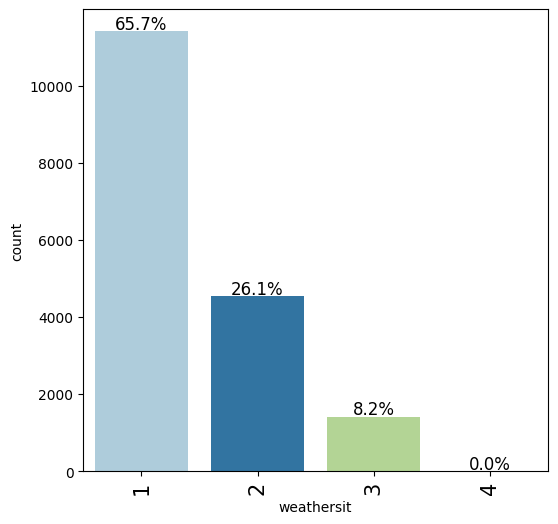

In [31]:
labeled_barplot(data, 'weathersit', perc=True)

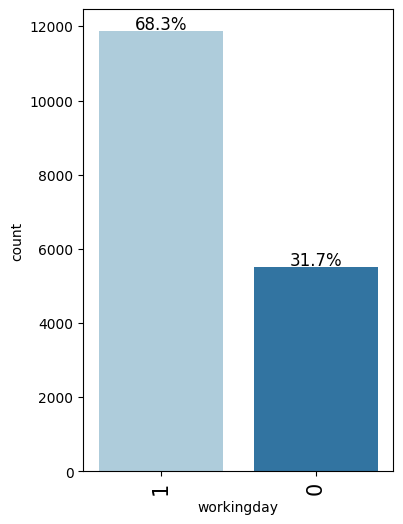

In [32]:
labeled_barplot(data, 'workingday', perc=True)

In [33]:
# Bivariate

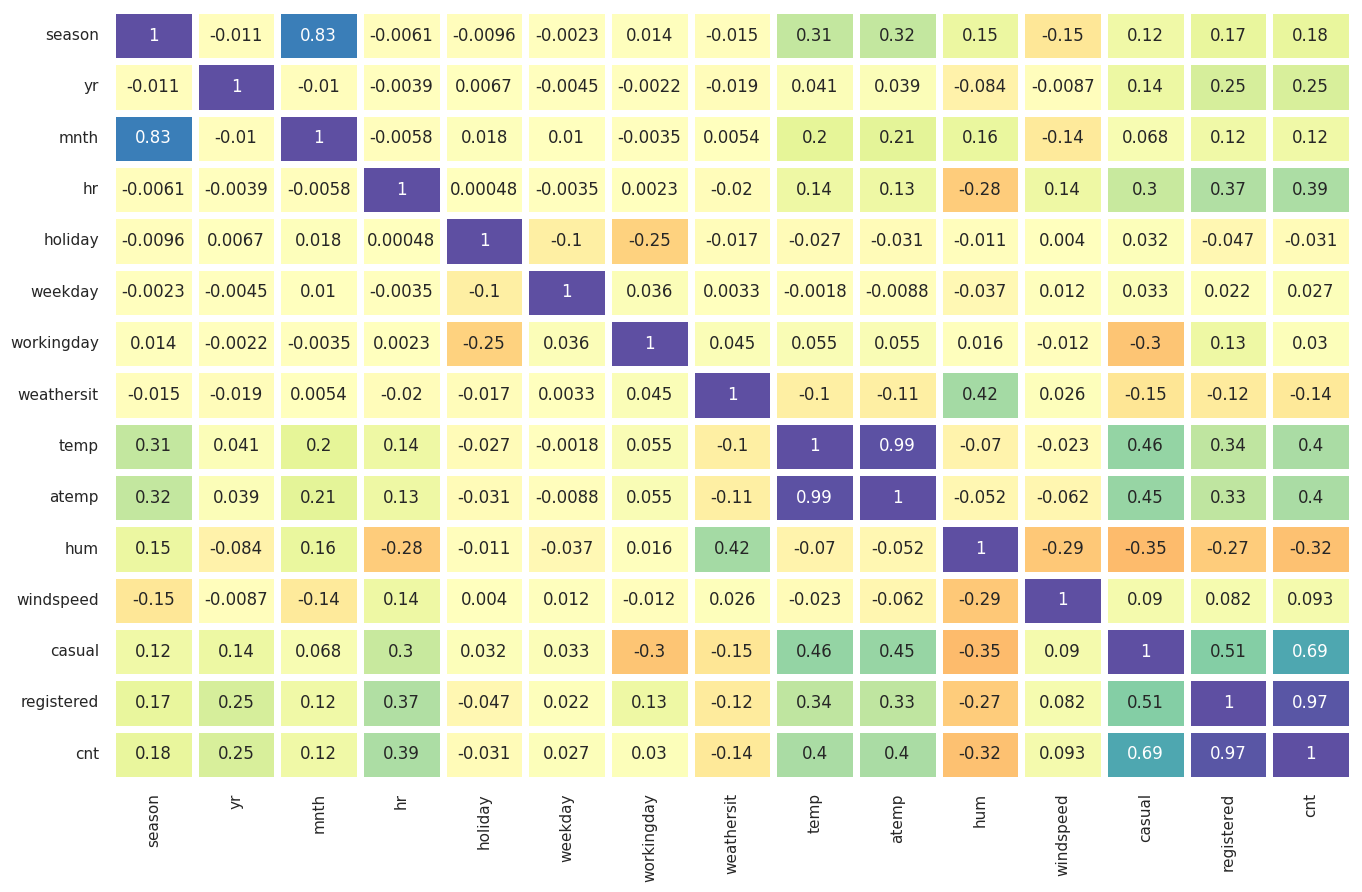

In [34]:
sns.set(rc = {"figure.figsize": (16, 10)})
sns.heatmap(data.corr(numeric_only=True),
    annot=True,
    linewidth = 5,
    center= 0 ,
    cbar = False,
    cmap = "Spectral")

plt.show()

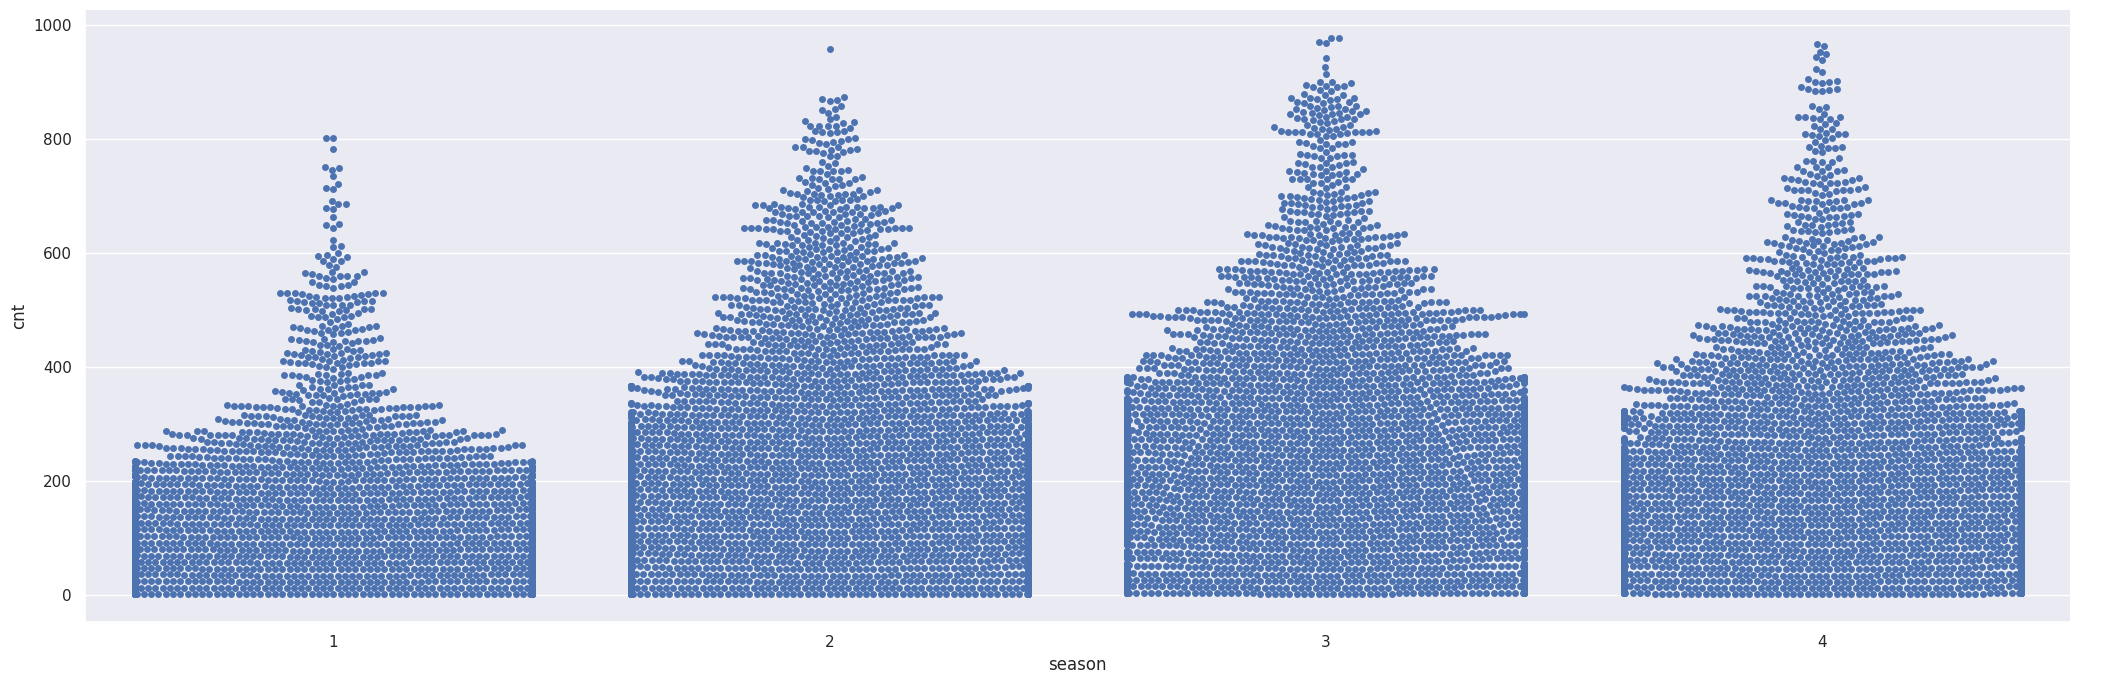

In [35]:
sns.set(rc = {"figure.figsize": (16, 10)})
sns.catplot(x=data['season'],
            y=data['cnt'],
            kind='swarm',
            height=7,
            aspect=3)

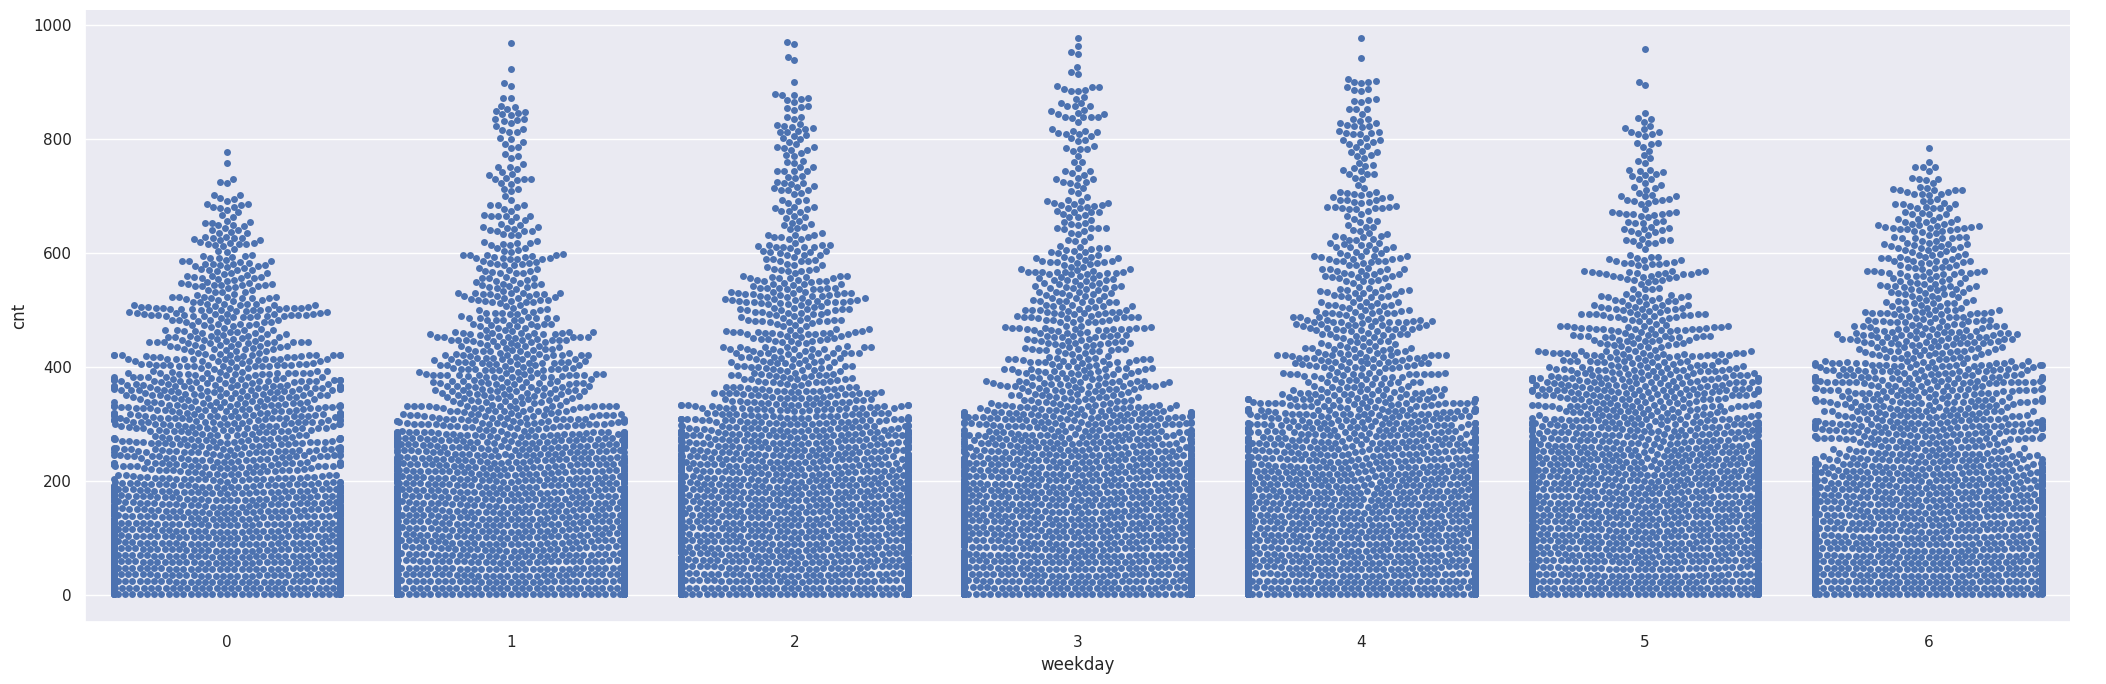

In [36]:
sns.set(rc={'figure.figsize':(21,7)})
sns.catplot(x=data["weekday"],
            y=data["cnt"],
            kind="swarm",
            height=7,
            aspect=3
            );

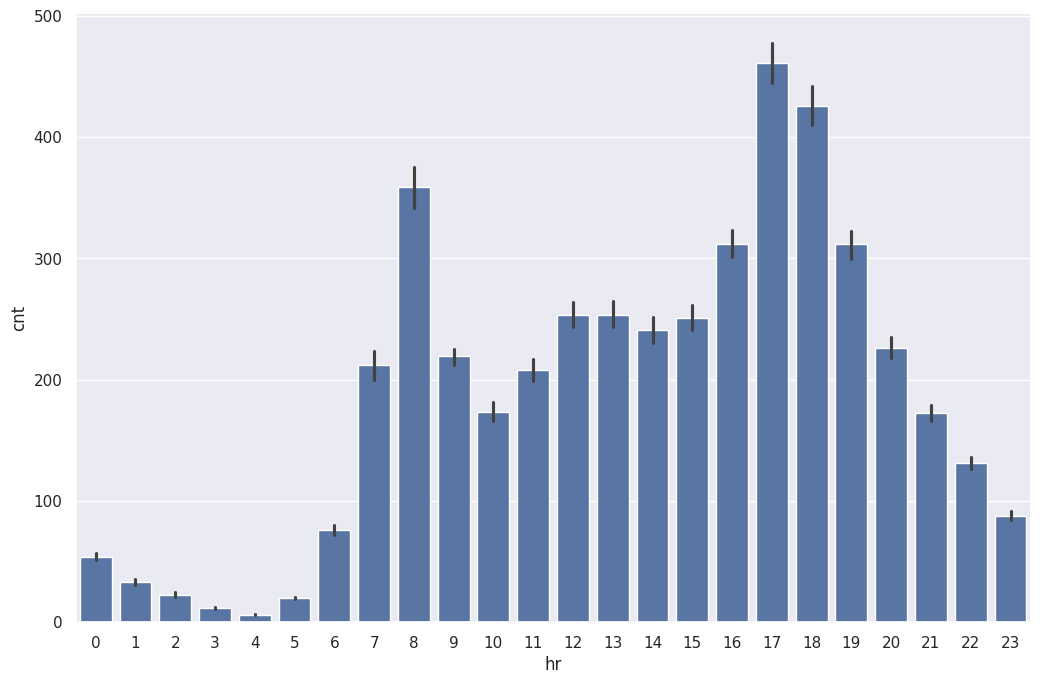

In [37]:
sns.catplot(x=data["hr"],
            y=data["cnt"],
            kind='bar',
            height=7,
            aspect=1.5,
            estimator=np.mean
            );

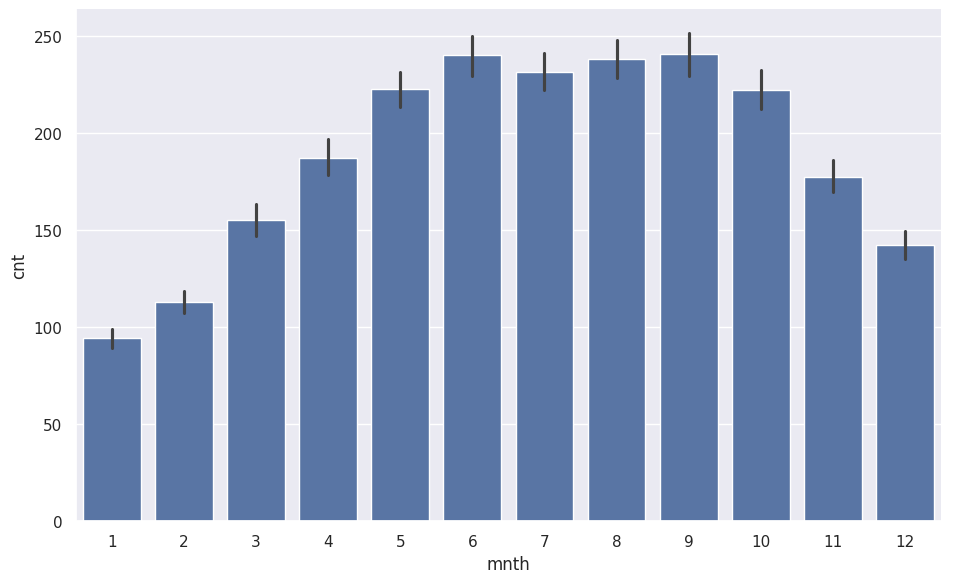

In [38]:
sns.catplot(x=data['mnth'],
            y=data['cnt'],
            kind='bar',
            height=6,
            aspect=1.6,
            estimator=np.mean);

<Axes: xlabel='yr,season'>

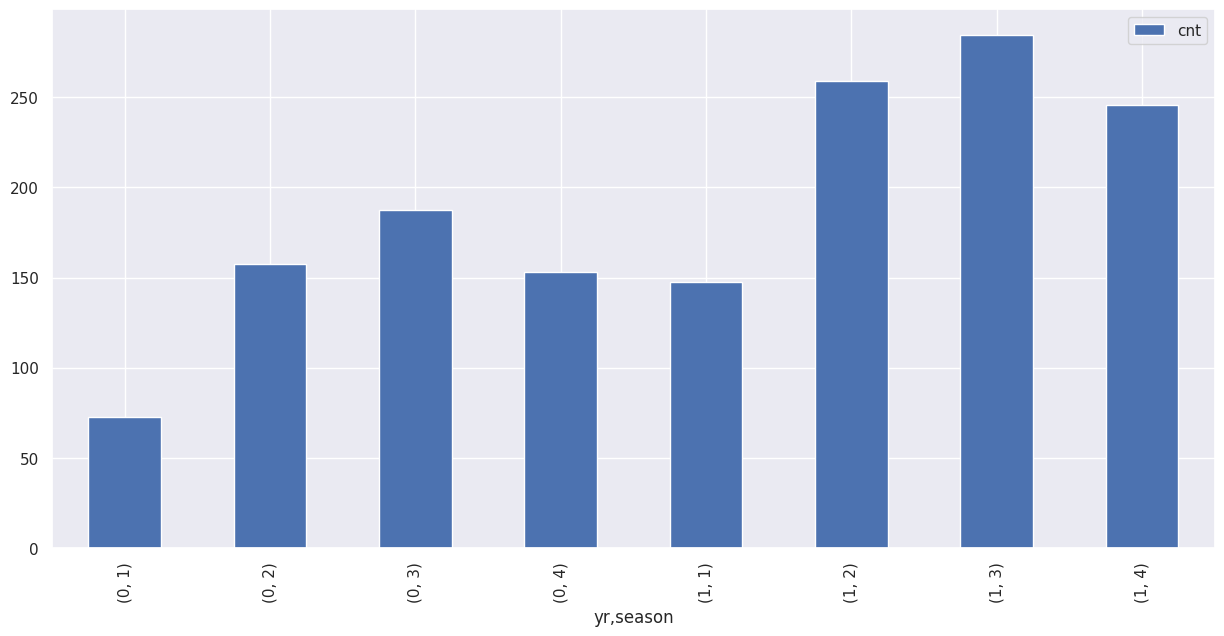

In [39]:
sns.set(rc={'figure.figsize':(15, 7)})
pd.pivot_table(data=data, index=['yr', 'season'], values='cnt', aggfunc='mean').plot(kind='bar')

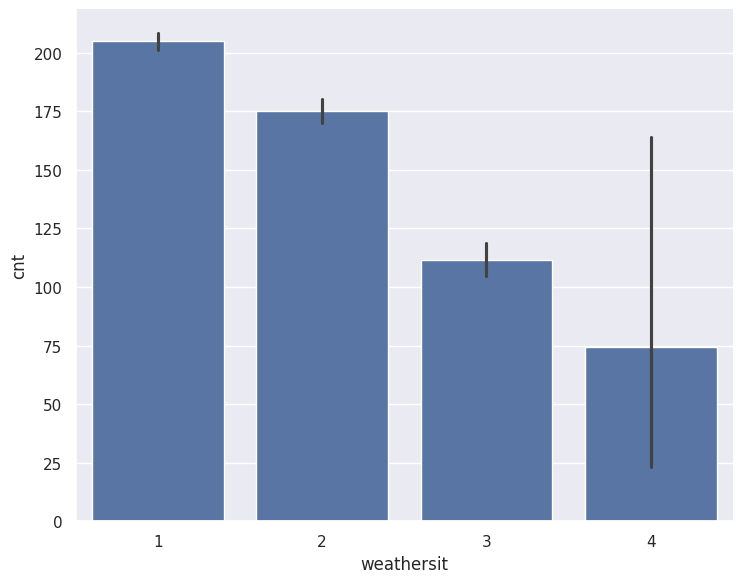

In [40]:
sns.catplot(x=data['weathersit'], y=data['cnt'], kind='bar', height=6, aspect=1.25, estimator=np.mean );

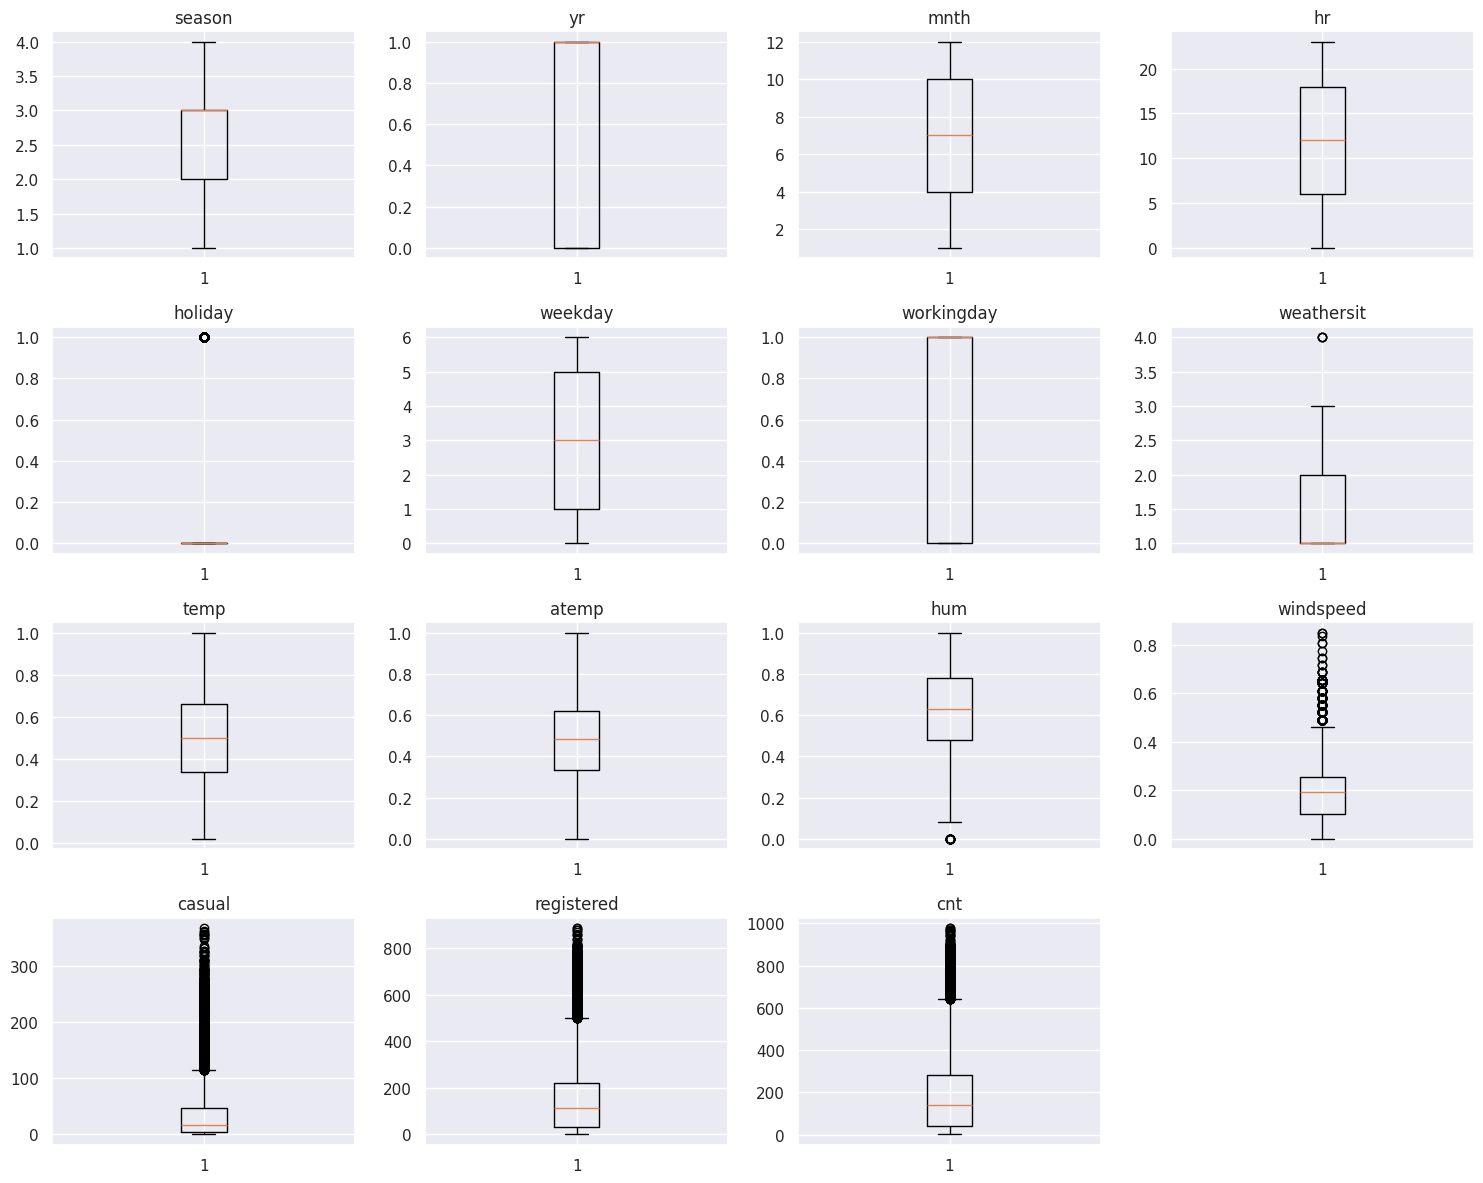

In [41]:
# outlier detection

numeric_columns = data.select_dtypes(include=np.number).columns.tolist()

plt.figure(figsize=(15,12))

for i, variable in enumerate(numeric_columns):
  plt.subplot(4, 4, i+1)
  plt.boxplot(data[variable])
  plt.tight_layout()
  plt.title(variable)

plt.show()

In [42]:
# Dropping casual and registered

data.drop(columns=['casual', 'registered'], inplace=True)

In [43]:
# Separating features and the target column

X = data.drop('cnt', axis=1)
y = data['cnt']

In [44]:
# Splitting data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=1, shuffle=True)                                                    )

SyntaxError: unmatched ')' (2940617704.py, line 2)

In [ ]:
X_train.shape, X_test.shapex

In [ ]:
# function to compute adjusted R-squared
def adj_r2_score(predictors, targets, predictions):
    r2 = r2_score(targets, predictions)
    n = predictors.shape[0]
    k = predictors.shape[1]
    return 1 - ((1 - r2) * (n - 1) / (n - k - 1))


# function to compute MAPE
def mape_score(targets, predictions):
    return np.mean(np.abs(targets - predictions) / targets) * 100


# function to compute different metrics to check performance of a regression model
def model_performance_regression(model, predictors, target):
    """
    Function to compute different metrics to check regression model performance

    model: regressor
    predictors: independent variables
    target: dependent variable
    """

    # predicting using the independent variables
    pred = model.predict(predictors)

    r2 = r2_score(target, pred)  # to compute R-squared
    adjr2 = adj_r2_score(predictors, target, pred)  # to compute adjusted R-squared
    rmse = np.sqrt(mean_squared_error(target, pred))  # to compute RMSE
    mae = mean_absolute_error(target, pred)  # to compute MAE
    mape = mape_score(target, pred)  # to compute MAPE

    # creating a dataframe of metrics
    df_perf = pd.DataFrame(
        {
            "RMSE": rmse,
            "MAE": mae,
            "R-squared": r2,
            "Adj. R-squared": adjr2,
            "MAPE": mape,
        },
        index=[0],
    )

    return df_perf

In [ ]:
##  Function to calculate r2_score and RMSE on train and test data
def get_model_score(model, flag=True):
    '''
    model : classifier to predict values of X

    '''
    # defining an empty list to store train and test results
    score_list=[]

    pred_train = model.predict(X_train)
    pred_test = model.predict(X_test)

    train_r2=metrics.r2_score(y_train,pred_train)
    test_r2=metrics.r2_score(y_test,pred_test)
    train_rmse=np.sqrt(metrics.mean_squared_error(y_train,pred_train))
    test_rmse=np.sqrt(metrics.mean_squared_error(y_test,pred_test))

    #Adding all scores in the list
    score_list.extend((train_r2,test_r2,train_rmse,test_rmse))

    # If the flag is set to True then only the following print statements will be dispayed, the default value is True
    if flag==True:
        print("R-sqaure on training set : ",metrics.r2_score(y_train,pred_train))
        print("R-square on test set : ",metrics.r2_score(y_test,pred_test))
        print("RMSE on training set : ",np.sqrt(metrics.mean_squared_error(y_train,pred_train)))
        print("RMSE on test set : ",np.sqrt(metrics.mean_squared_error(y_test,pred_test)))

    # returning the list with train and test scores
    return score_list

In [ ]:
dtree=DecisionTreeRegressor(random_state=1)
dtree.fit(X_train,y_train)

In [ ]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [ ]:
dtree_model_train_perf=model_performance_regression(dtree, X_train,y_train)
print("Training performance \n",dtree_model_train_perf)

In [ ]:
dtree_model_test_perf=model_performance_regression(dtree, X_test,y_test)
print("Testing performance \n",dtree_model_test_perf)